# CISC7204 Assignment 01 - Module 02 - Lab02 Data Wrangling - Laptop Pricing


In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib
matplotlib.use("Agg")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod1.csv"
df = pd.read_csv(DATA_URL)
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
pd.set_option("display.max_columns", None)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (238, 12)


  Manufacturer  Category     Screen  GPU  OS  CPU_core  Screen_Size_cm  \
0         Acer         4  IPS Panel    2   1         5          35.560   
1         Dell         3    Full HD    1   1         3          39.624   
2         Dell         3    Full HD    1   1         7          39.624   
3         Dell         4  IPS Panel    2   1         5          33.782   
4           HP         4    Full HD    2   1         7          39.624   

   CPU_frequency  RAM_GB  Storage_GB_SSD  Weight_kg  Price  
0            1.6       8             256       1.60    978  
1            2.0       4             256       2.20    634  
2            2.7       8             256       2.20    946  
3            1.6       8             128       1.22   1244  
4            1.8       8             256       1.91    837  

## Task 1: Identify Missing Values

In [2]:
print("Missing values before cleaning:")
print(df.isna().sum())

Missing values before cleaning:
Manufacturer      0
Category          0
Screen            0
GPU               0
OS                0
CPU_core          0
Screen_Size_cm    4
CPU_frequency     0
RAM_GB            0
Storage_GB_SSD    0
Weight_kg         5
Price             0
dtype: int64


## Task 2: Replace Missing Values

In [3]:
laptop_df = df.copy()
laptop_df["Weight_kg"] = pd.to_numeric(laptop_df["Weight_kg"], errors="coerce")
laptop_df["Screen_Size_cm"] = pd.to_numeric(laptop_df["Screen_Size_cm"], errors="coerce")

mean_weight = laptop_df["Weight_kg"].mean()
common_screen_size = laptop_df["Screen_Size_cm"].mode()[0]

laptop_df["Weight_kg"].fillna(mean_weight, inplace=True)
laptop_df["Screen_Size_cm"].fillna(common_screen_size, inplace=True)

print("Mean Weight_kg used:", round(mean_weight, 3))
print("Most frequent Screen_Size_cm used:", common_screen_size)
print("\nMissing values after replacement:")
print(laptop_df.isna().sum())

Mean Weight_kg used: 1.862
Most frequent Screen_Size_cm used: 39.624

Missing values after replacement:
Manufacturer      0
Category          0
Screen            0
GPU               0
OS                0
CPU_core          0
Screen_Size_cm    0
CPU_frequency     0
RAM_GB            0
Storage_GB_SSD    0
Weight_kg         0
Price             0
dtype: int64


## Task 3: Correct Data Types

In [4]:
laptop_df["Weight_kg"] = laptop_df["Weight_kg"].astype(float)
laptop_df["Screen_Size_cm"] = laptop_df["Screen_Size_cm"].astype(float)
laptop_df.dtypes

Manufacturer       object
Category            int64
Screen             object
GPU                 int64
OS                  int64
CPU_core            int64
Screen_Size_cm    float64
CPU_frequency     float64
RAM_GB              int64
Storage_GB_SSD      int64
Weight_kg         float64
Price               int64
dtype: object

## Task 4: Standardization And Normalization

In [5]:
laptop_df["Screen_Size_inch"] = laptop_df["Screen_Size_cm"] / 2.54
laptop_df["Weight_pounds"] = laptop_df["Weight_kg"] * 2.205
laptop_df.drop(columns=["Screen_Size_cm", "Weight_kg"], inplace=True)

laptop_df["CPU_frequency"] = laptop_df["CPU_frequency"] / laptop_df["CPU_frequency"].max()

laptop_df[["Screen_Size_inch", "Weight_pounds", "CPU_frequency"]].head()

   Screen_Size_inch  Weight_pounds  CPU_frequency
0              14.0        3.52800       0.551724
1              15.6        4.85100       0.689655
2              15.6        4.85100       0.931034
3              13.3        2.69010       0.551724
4              15.6        4.21155       0.620690

## Task 5: Binning The Price Attribute

Low       160
Medium     72
High        6
Name: Price-binned, dtype: int64


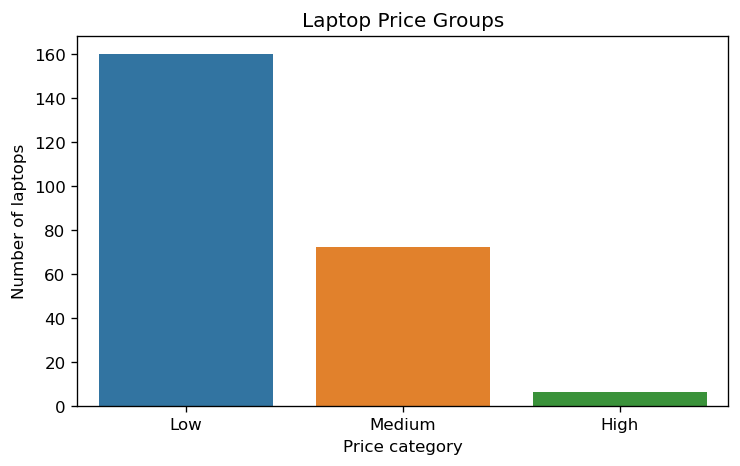

In [6]:
bins = np.linspace(laptop_df["Price"].min(), laptop_df["Price"].max(), 4)
group_names = ["Low", "Medium", "High"]
laptop_df["Price-binned"] = pd.cut(laptop_df["Price"], bins=bins, labels=group_names, include_lowest=True)

print(laptop_df["Price-binned"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=laptop_df, x="Price-binned", order=group_names)
plt.title("Laptop Price Groups")
plt.xlabel("Price category")
plt.ylabel("Number of laptops")
plt.show()

## Task 6: Indicator Variables

In [7]:
screen_dummies = pd.get_dummies(laptop_df["Screen"], prefix="Screen")
laptop_df = pd.concat([laptop_df.drop(columns=["Screen"]), screen_dummies], axis=1)
laptop_df.head()

  Manufacturer  Category  GPU  OS  CPU_core  CPU_frequency  RAM_GB  \
0         Acer         4    2   1         5       0.551724       8   
1         Dell         3    1   1         3       0.689655       4   
2         Dell         3    1   1         7       0.931034       8   
3         Dell         4    2   1         5       0.551724       8   
4           HP         4    2   1         7       0.620690       8   

   Storage_GB_SSD  Price  Screen_Size_inch  Weight_pounds Price-binned  \
0             256    978              14.0        3.52800          Low   
1             256    634              15.6        4.85100          Low   
2             256    946              15.6        4.85100          Low   
3             128   1244              13.3        2.69010          Low   
4             256    837              15.6        4.21155          Low   

   Screen_Full HD  Screen_IPS Panel  
0               0                 1  
1               1                 0  
2               1   